# Análisis de IPQ en videoclip interactivo en VR

**Instrumento y administración**: 

Se utilizaron los 14 items en español del IPQ publicados por Castro et al. (2026), [adaptación española del ITQ e IPQ](https://doi.org/10.1007/s10055-025-01301-2)


**Modelo principal:** 

Las tres dimensiones se calculan con el modelo factorial revisado que presenta el artículo. Este modelo retiró de involucramiento el ítem 14 por sus cargas en varios factores. Se muestra además el promedio de involucramiento con los cuatro ítems originales como análisis de sensibilidad. El ítem 8 se informa por separado como presencia general.


**NOTA:** 

El término EDA en este notebook significa análisis exploratorio de datos, no Event-Driven Architecture. 

**Fuente de datos:**

Resultados-IPQ-actualizados.xlsx, exportacion de KoboToolbox. Solo se analizan las respuestas con autorización y los datos no serán subidos al repositorio. Para ver los datos contactar a la investigadora por medio de correo: gar22869@uvg.edu.gt


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.patches import Patch

In [3]:
path_archivo = [
    Path("Resultados-IPQ-actualizados.xlsx"),
]

archivo = next((ruta for ruta in path_archivo if ruta.exists()), None)

df = pd.read_excel(archivo)

## 1. Análisis exploratorio de datos - EDA

In [4]:
# posiciones verificadas del xlsForm y comprobar el número de items
columnas_ipq = {f"q{i}": df.columns[12 + i] for i in range(1, 15)}
for i, encabezado in enumerate(columnas_ipq.values(), start=1):
    assert str(encabezado).startswith(f"{i}."), f"Cambió el orden del ítem {i}"
columnas_ipq

{'q1': '1. ¿Cómo de consciente eras del mundo real que te rodeaba mientras veías el mundo virtual? (E.j.. Sonidos, la temperatura de habitación, otras personas, etcétera.)?',
 'q2': '2. ¿Te parecía real el mundo virtual?',
 'q3': '3. Tuve la sensación de actuar dentro del espacio virtual más que manipular algo desde afuera',
 'q4': '4. ¿Hasta qué punto te parecía consistente tu experiencia en el ambiente virtual con tu experiencia en el mundo real?',
 'q5': '5. ¿Cómo de real te parecía el mundo virtual?',
 'q6': '6. No me sentí presente en el espacio virtual.',
 'q7': '7. No fui consciente del ambiente real.',
 'q8': '8. En el mundo generado por ordenador tenía la sensación de “estar allí”.',
 'q9': '9. Me sentía rodeado de alguna forma por el mundo virtual.',
 'q10': '10. Me sentía presente en el espacio virtual.',
 'q11': '11. A pesar de todo, presté atención al ambiente real.',
 'q12': '12. El mundo virtual me pareció más realista que el mundo real.',
 'q13': '13. Sentí como si sólo

## Tabla de ítems y aspectos evaluados en el IPQ


| Ítem | Dimensión  | Aspecto evaluado |
| :--- | :---: | ---: |
| 1 | Involucramiento | Grado de conciencia del entorno real mientras el usuario participa en la experiencia virtual |
| 2 | Realismo  | Percepción de qué tan real parece el mundo real |
| 3 | Presencia espacial | Sensasión de actuar dentro del entorno virtual en lugar de controlarlo afuera |
| 4 | Realismo | Consistencia de la experiencia virtual con las del mundo real |
| 5 | Realismo | Percepción del entorno como un mundo imaginado o indistinguible del mundo real |
| 6 | Sensación de encontrase físicamente | presente dentro del espacio virtual |
| 7 | Involucramiento | Pérdida de conciencia del entorno físico durante la experiencia virtual |
| 8 | Presencia general | Sensación general de estar allí, dentro del mundo virtual |
| 9 | Presencia general | Sensación de estar rodeado por el entorno virtual |
| 10 | Presencia espacial | Sensación de estar rodeado por el entorno virtual |
| 11 | Involucramiento | Atención que el usuario continua prestando al ambiente real durante la experiencia |
| 12 | Realismo | Percepción de que el mundo virtual parece más realista que el mundo físico |
| 13 | Presencia espacial  | Sensación de estar observando únicamente imágenes en lugar de encontrarse con el entorno |
| 14 | Involucramiento | Grado en que el mundo virtual cautiva completamente la atención del usuario |



In [5]:
consentidas = df.loc[
    pd.to_numeric(df["research_use_flag"], errors="coerce").eq(1)
].copy()

respuestas = pd.DataFrame({
    nombre: pd.to_numeric(consentidas[columna], errors="coerce")
    for nombre, columna in columnas_ipq.items()
}, index=consentidas.index)
respuestas

,q1,q2,q3,q4,q5,q6,q7,q8,q9,q10,q11,q12,q13,q14
0,-3,-2.0,3,2.0,2,3,3,3.0,3,3.0,-2.0,1,-3.0,3
1,1,-1.0,3,2.0,1,3,-1,3.0,3,3.0,1.0,-3,-2.0,3
2,-2,-2.0,2,1.0,0,2,0,1.0,1,1.0,-1.0,-3,-3.0,1
3,-1,0.0,2,-1.0,1,-2,2,2.0,3,2.0,-1.0,2,-3.0,3
4,1,2.0,2,0.0,-2,2,3,3.0,2,3.0,-1.0,-2,-1.0,1
5,-3,NaN,3,NaN,2,3,-3,3.0,3,3.0,-3.0,0,-3.0,3
6,2,-2.0,3,3.0,3,0,0,3.0,3,NaN,NaN,3,0.0,3
7,-3,3.0,-3,-2.0,-1,3,3,-3.0,-3,-3.0,-2.0,-3,-3.0,1
8,-1,-2.0,3,2.0,1,2,2,3.0,3,2.0,-2.0,2,NaN,2
9,-3,-3.0,3,1.0,2,2,-2,3.0,3,3.0,-3.0,2,1.0,-1


In [6]:
faltantes_por_fila = respuestas.isna().sum(axis=1)
revision = pd.DataFrame({
    "Medida": [
        "Registros exportados", "Registros con consentimiento",
        "IPQ completo (14 ítems)", "IPQ con 1 respuesta faltante",
        "IPQ con 2 respuestas faltantes", "IPQ con 3 o más respuestas faltantes",
    ],
    "Cantidad": [
        len(df), len(consentidas), int((faltantes_por_fila == 0).sum()),
        int((faltantes_por_fila == 1).sum()), int((faltantes_por_fila == 2).sum()),
        int((faltantes_por_fila >= 3).sum())
    ]
})
display(revision)

,Medida,Cantidad
0,Registros exportados,39
1,Registros con consentimiento,39
2,IPQ completo (14 ítems),35
3,IPQ con 1 respuesta faltante,1
4,IPQ con 2 respuestas faltantes,3
5,IPQ con 3 o más respuestas faltantes,0


# 2. Puntuaciones del IPQ

[Adaptación española, Apéndice 2](https://doi.org/10.1007/s10055-025-01301-2)

- Se invierten los items 2 y 4 (anclajes del realismo y consistencia)
- 11: atencion al entorno real
- 13: sensacion de mirar fotografías
- 6: conserva su signo porque sus extremos van de "no me sentí presente"
- 1: se conserva el signo también

Las puntuaciones de cada dimensión son el promedio de sus ítems. 


### ⭐ Tabla Perfil IPQ

In [7]:
items_orientados = respuestas.copy()

for nombre in ("q2", "q4", "q11", "q13"):
    items_orientados[nombre] = -items_orientados[nombre]

def promedio_completo(columnas):
    valores = items_orientados[columnas]
    return valores.mean(axis=1).where(valores.notna().all(axis=1))

puntuaciones = pd.DataFrame(index=respuestas.index)
puntuaciones["Presencia general (ítem 8)"] = items_orientados["q8"]
puntuaciones["Presencia espacial (5 ítems)"] = promedio_completo(["q3", "q6", "q9", "q10", "q13"])
puntuaciones["Involucramiento (3 ítems, modelo revisado)"] = promedio_completo(["q1", "q7", "q11"])
puntuaciones["Realismo (4 ítems)"] = promedio_completo(["q2", "q4", "q5", "q12"])
puntuaciones["Involucramiento (4 ítems, sensibilidad)"] = promedio_completo(["q1", "q7", "q11", "q14"])

tabla_puntuaciones = pd.DataFrame({
    "Indicador": puntuaciones.columns,
    "n": puntuaciones.count().to_numpy(),
    "Media": puntuaciones.mean().to_numpy(),
    "Desviación estándar": puntuaciones.std(ddof=1).to_numpy(),
    "Mediana": puntuaciones.median().to_numpy(),
    "Respuestas positivas": puntuaciones.gt(0).sum().to_numpy()
})

display(tabla_puntuaciones.round(2))


,Indicador,n,Media,Desviación estándar,Mediana,Respuestas positivas
0,Presencia general (ítem 8),38,2.05,1.14,2.00,36
1,Presencia espacial (5 ítems),36,1.97,0.86,2.00,35
2,"Involucramiento (3 ítems, modelo revisado)",38,0.38,0.89,0.33,23
3,Realismo (4 ítems),38,0.15,0.98,0.38,24
4,"Involucramiento (4 ítems, sensibilidad)",38,0.76,0.75,0.88,30


### ⭐ Perfil medio del IPQ

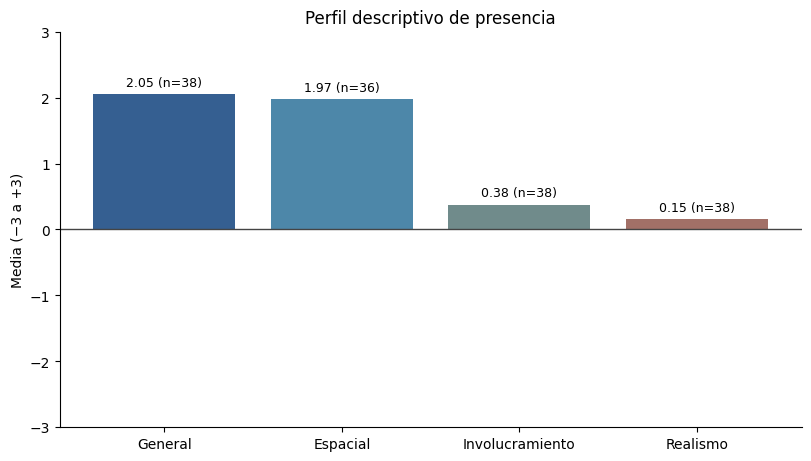

In [8]:
perfil = puntuaciones.iloc[:, :4]
medias = perfil.mean()
etiquetas = ["General", "Espacial", "Involucramiento", "Realismo"]
colores = ["#355f91", "#4d87a9", "#708b8b", "#a27067"]
fig, eje = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
barras = eje.bar(etiquetas, medias.values, color=colores)
eje.axhline(0, color="#444444", linewidth=1)
eje.set(title="Perfil descriptivo de presencia", ylabel="Media (−3 a +3)", ylim=(-3, 3))
eje.spines[["top", "right"]].set_visible(False)
for barra, media, n in zip(barras, medias, perfil.count()):
    desplazamiento = 0.08 if media >= 0 else -0.22
    eje.text(barra.get_x() + barra.get_width()/2, media + desplazamiento,
             f"{media:.2f} (n={n})", ha="center", va="bottom", fontsize=9)
plt.show()


Lo que se puede observar en la gráfica de perfil descriptivo de presencia es que la presencia general obtuvo una media de 2.05 (n=38), la presencia espacial tuvo 1.97 (n=36). Lo que indica que los valores tienen una percepción positiva de estar dentro del entorno virtual. Esto muestra que los participantes lograron experimentar una sensación de presencia durante el videoclip.

# 3. Visualizaciones de los resultados


Los siguientes gráficos permiten el entendimiento del perfil de medias para evaluar la variavilidad de personas, orientación de las respuestas, diferencia entre ítems y solidez del análisis de involucramiento. 

Se usa el modelo revisado de Castro et al. (2026). 
- ítem 8 para la presencia general 
- ítems para la presencia espacial: 3, 6, 9, 10 y 13 
- ítems para el involucramiento:  1, 7 y 11
- ítems para el realismo:  2, 4, 5 y 12
- ítem 14 queda afuera del involucramiento principal, pero se usa como sensibilidad


Los valores más altos en la escala de -3 a 3 indican más presencia o intensidad de la dimensión. Las respuestas 2, 4, 11 y 13 ya están invertidas. 


In [9]:
# Gráficas complementarias: definiciones basadas en el modelo revisado.
colores_ipq = {
    "General": "#355F91", "Espacial": "#4D87A9",
    "Involucramiento": "#708B8B", "Realismo": "#A27067",
    "Excluido": "#7E8792"
}
dimensiones_ipq = pd.DataFrame({
    "General": puntuaciones["Presencia general (ítem 8)"],
    "Espacial": puntuaciones["Presencia espacial (5 ítems)"],
    "Involucramiento": puntuaciones["Involucramiento (3 ítems, modelo revisado)"],
    "Realismo": puntuaciones["Realismo (4 ítems)"]
})
# Etiquetas abreviadas
items_ipq = [
    ("q8", "Estar allí", "General"),
    ("q3", "Actuar dentro del entorno", "Espacial"),
    ("q6", "Sentirse presente en el espacio", "Espacial"),
    ("q9", "Entorno virtual envolvente", "Espacial"),
    ("q10", "Presente en espacio virtual", "Espacial"),
    ("q13", "No ver solo fotografías", "Espacial"),
    ("q1", "Desatender entorno real", "Involucramiento"),
    ("q7", "No ser consciente entorno real", "Involucramiento"),
    ("q11", "No atender entorno real", "Involucramiento"),
    ("q2", "Realidad percibida", "Realismo"),
    ("q4", "Consistencia con mundo real", "Realismo"),
    ("q5", "Realidad frente a imaginación", "Realismo"),
    ("q12", "Más realista que mundo real", "Realismo"),
]
# Ítem 14 se mantiene fuera del involucramiento principal por la revisión factorial.
plt.rcParams.update({"font.size": 10, "axes.titlesize": 14, "axes.labelsize": 11, "figure.facecolor": "white"})


# 3.1 Promedio por ítem: ¿Qué aspectos destacaron?

La media global puede ocultar diferencias entre afirmaciones. Esta gráfica identifica fortalezas y aspectos mejorables sin combinar ítems con significados distintos. 

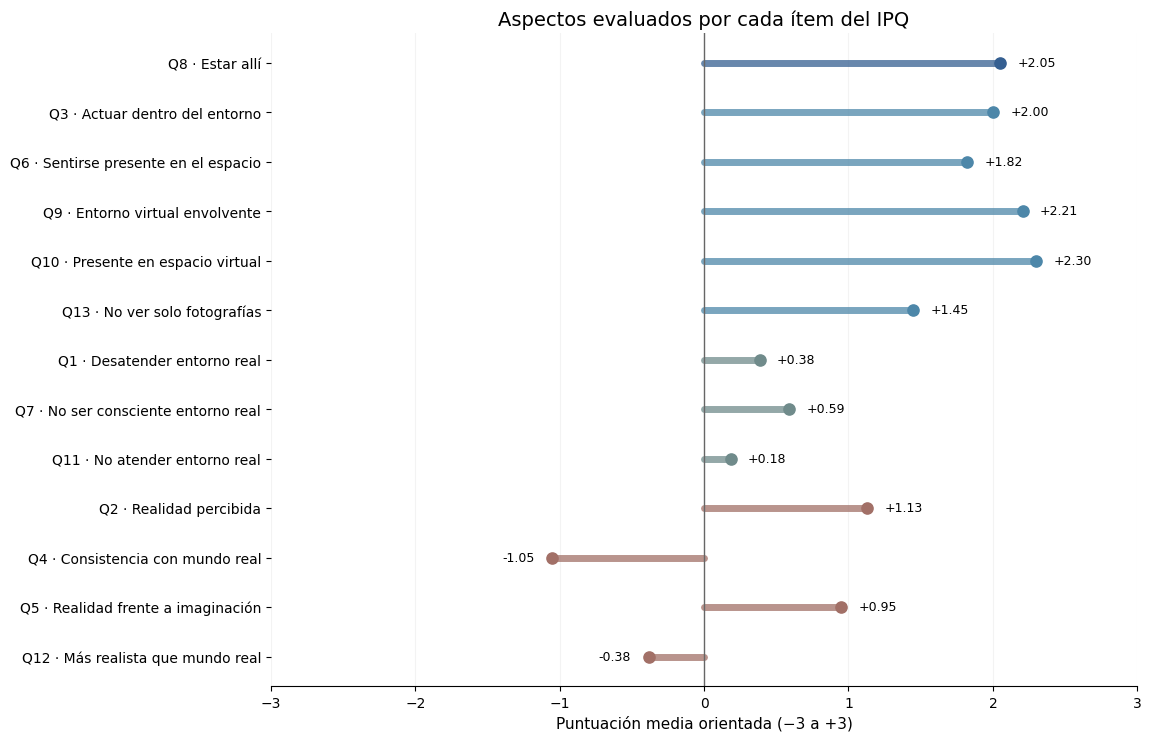

In [10]:
fig, ax = plt.subplots(figsize=(11.4, 7.3), constrained_layout=True)
Y=np.arange(len(items_ipq))
for i, (item, texto, dimension) in enumerate(items_ipq):
    media=items_orientados[item].mean()
    color=colores_ipq[dimension]
    ax.plot([0,media],[i,i],lw=5,color=color,alpha=.75,solid_capstyle='round')
    ax.scatter(media,i,color=color,s=65,zorder=4)
    ax.text(media + (.12 if media>=0 else -.12),i,f'{media:+.2f}',
            va='center',ha='left' if media>=0 else 'right',fontsize=9)
ax.set_yticks(Y,[f'{item[0].upper()} · {item[1]}' for item in items_ipq])
ax.invert_yaxis()
ax.set(xlim=(-3,3),xlabel='Puntuación media orientada (−3 a +3)',title='Aspectos evaluados por cada ítem del IPQ')
ax.axvline(0,color='#666666',lw=1)
ax.grid(axis='x',alpha=.15)
ax.spines[['top','right','left']].set_visible(False)
plt.show()


Acerca de los aspectos evaluados por cada ítem del IPQ, en el gráfico se puede ver la representación de las puntuaciones promedio de los ítems para las diferentes dimensiones de presencia. Sobre la presencia espacial, los valores más altos son del ítem Q10 (2.30), seguido del ítem Q9 (2.21). Por otra parte, los ítems Q3(2.00) y Q6(1.82) las medidas obtuvidas indican que los participantes percibieron de manera positiva su ubicación y participación dentro del entorno virtual.

En constraste los ítems Q1(0.38), Q7(0.59) y Q11(0.18) de involucramiento se obtuvieron valores moderados. Lo que evidencia que los usuarios mantuvieron cierto grado de conciencia del entorno físico durante la experiencia, por lo que su atención no estuvo totalmente concentrada en el mundo virtual.

La dimensión de realismo, se observó varias diferencias entre los aspectos evaluados. Los ítems Q2(1.13) y Q5(0.95) a diferencia de los ítems Q4(-1.15) y Q12(-0.38) el contraste muestra que los participantes percibieron algunas características realistas en el mundo virtual, aunque no necesariamente consideraron que el entorno virtual fuera consistente o más realista que el mundo físico.  

# ⭐ 3.2 Distribución de las tres dimensiones y presencia general

Los puntos son los participantes y las cajas resumen mediana y rango intercuartílico. Esta gráfica aclara si un promedio alto es compartido por muchos usuarios o si depende de pocos valores.

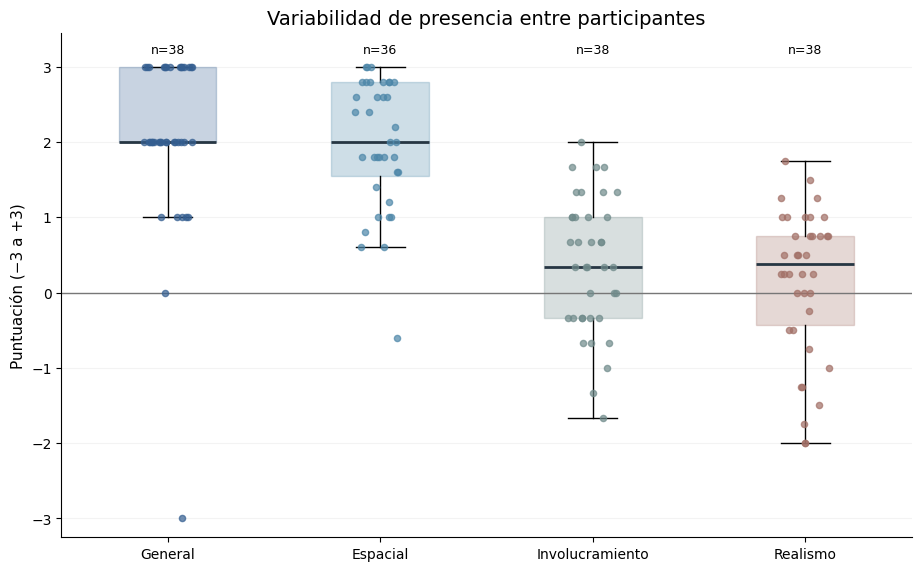

In [11]:
fig, ax = plt.subplots(figsize=(9.1,5.6),constrained_layout=True)
etiquetas=list(dimensiones_ipq)
datos=[dimensiones_ipq[c].dropna().values for c in etiquetas]

box=ax.boxplot(datos,positions=np.arange(1,5),widths=.46,patch_artist=True,
               showfliers=False,medianprops={'color':'#263643','linewidth':2})

for patch, nombre in zip(box['boxes'],etiquetas):
    patch.set(facecolor=colores_ipq[nombre],alpha=.27,edgecolor=colores_ipq[nombre])
semilla=np.random.default_rng(42)

for i,(nombre,serie) in enumerate(zip(etiquetas,datos),start=1):
    desplazamiento=semilla.uniform(-.12,.12,len(serie))
    ax.scatter(np.full(len(serie),i)+desplazamiento,serie,s=20,
               color=colores_ipq[nombre],alpha=.7,zorder=3)
    ax.text(i,3.17,f'n={len(serie)}',ha='center',fontsize=9)
    
ax.set(ylim=(-3.25,3.45),ylabel='Puntuación (−3 a +3)',title='Variabilidad de presencia entre participantes')
ax.set_xticks(range(1,5),etiquetas)
ax.axhline(0,color='#777777',lw=1)
ax.grid(axis='y',alpha=.14)
ax.spines[['top','right']].set_visible(False)
plt.show()


La distribución de las puntuaciones individuales mediante diagramas de caja. Se observa que la presencia general y la presencia espacial muestran medianas cercanas a 2.0 con una concentración de respuestas en valores positivos. Lo que demuestra que la mayoría de participantes experimiento una sensación favorable de presencia dentro del entorno virtual. AUnque tambien hay algunas puntuaciones inferiores, lo que muestra uqe la experiencia no fue percibida de la misma manera para todos los usuarios. 

Por otro lado, las dimensiones de involucramiento y realismo presentan una mayor dispersión de respuestas alrededor del punto neutral. En el involucramiento se observan puntuaciones tanto negativas como positivas. Y en el realismo presenta una distribución similar. La variación demuestra que la capacidad de la experiencia de captar la atención y transmitir una sensasión de realismo fue diferente entre los participantes. A pesar de que los promedios generales permiten identificar tendencias, las diferencias individuales muestran que la percepción de presencia no fue uniforme en todas sus dimensiones. 

# 3.3 Proporción de puntuaciones positivas, neutras y negativas

Se clasifican descriptivamente cada puntuación de dimensión individual como negatica (<0), neutral (=0) o positiva (>0). Para ayudar a mostrar el sentido de las respuestas 


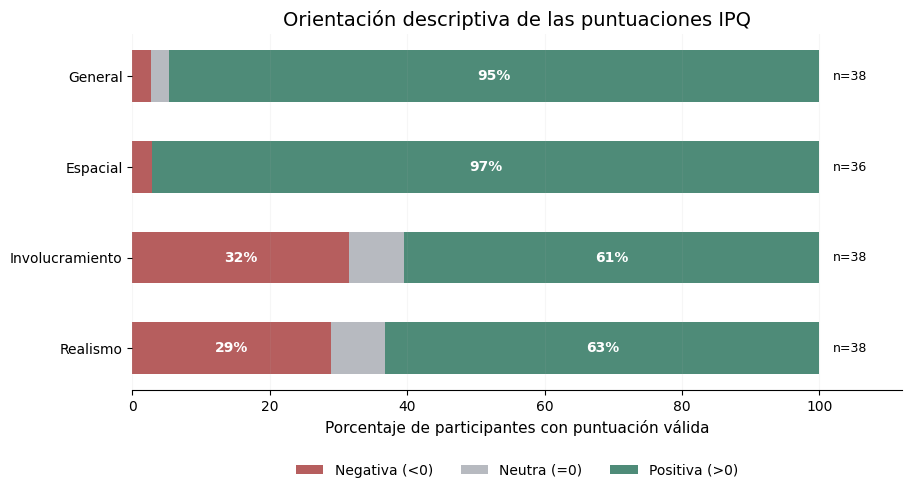

In [12]:
fig,ax=plt.subplots(figsize=(9,4.8),constrained_layout=True)

orden=['General','Espacial','Involucramiento','Realismo']
categorias=['Negativa (<0)','Neutra (=0)','Positiva (>0)']
colores=['#B65E5E','#B7BAC0','#4E8B78']

for y,dim in enumerate(orden):
    serie=dimensiones_ipq[dim].dropna()
    partes=[(serie<0).mean()*100,(serie==0).mean()*100,(serie>0).mean()*100]
    izquierda=0
    for cat,color,parte in zip(categorias,colores,partes):
        ax.barh(y,parte,left=izquierda,color=color,height=.57,label=cat if y==0 else None)
        if parte>8:ax.text(izquierda+parte/2,y,f'{parte:.0f}%',ha='center',va='center',color='white' if cat!='Neutra (=0)' else '#333333',fontweight='bold',fontsize=10)
        izquierda+=parte
    ax.text(102,y,f'n={len(serie)}',va='center',fontsize=9)
    
ax.set_yticks(range(4),orden)
ax.invert_yaxis()
ax.set(xlim=(0,112),xlabel='Porcentaje de participantes con puntuación válida',title='Orientación descriptiva de las puntuaciones IPQ')
ax.set_xticks([0,20,40,60,80,100])
ax.grid(axis='x',alpha=.1)
ax.legend(loc='lower center',bbox_to_anchor=(.5,-.28),ncol=3,frameon=False)
ax.spines[['top','right','left']].set_visible(False)
plt.show()


En esta gráfica lo que se muestra es la proporción de participantes que obtuvieron puntuaciones positivos, neutros o negativos en las diferentes dimensiones. 

En cuanto presencia general, el 95 % de los participantes (36 de 38) obtuvo una puntuación superior a cero, mientras que en presencia espacial esta proporción alcanzó el 97 % (35 de 36). Estos resultados muestran una tendencia ampliamente favorable en la percepción de estar dentro del entorno virtual. 

Por otro lado, en la dimensión de involucramiento, el 61 % de los participantes obtuvo puntuaciones positivas, el 32 % negativas y aproximadamente el 8 % neutras. En el caso del realismo, el 63 % registró puntuaciones positivas, el 29 % negativas y alrededor del 8 % neutras. Aunque en ambas dimensiones predominan las puntuaciones superiores a cero, existe un grupo considerable de participantes que presentó valoraciones negativas. Esto permite identificar que la experiencia consiguió generar una percepción positiva de presencia espacial en la mayoría de los usuarios, pero la capacidad de captar completamente su atención y ofrecer una sensación de realismo fue más variable.




# 3.4 Distribución Likert de cada ítem (-3 a +3)

Se muestra toda la frecuencia de las 7 opciones

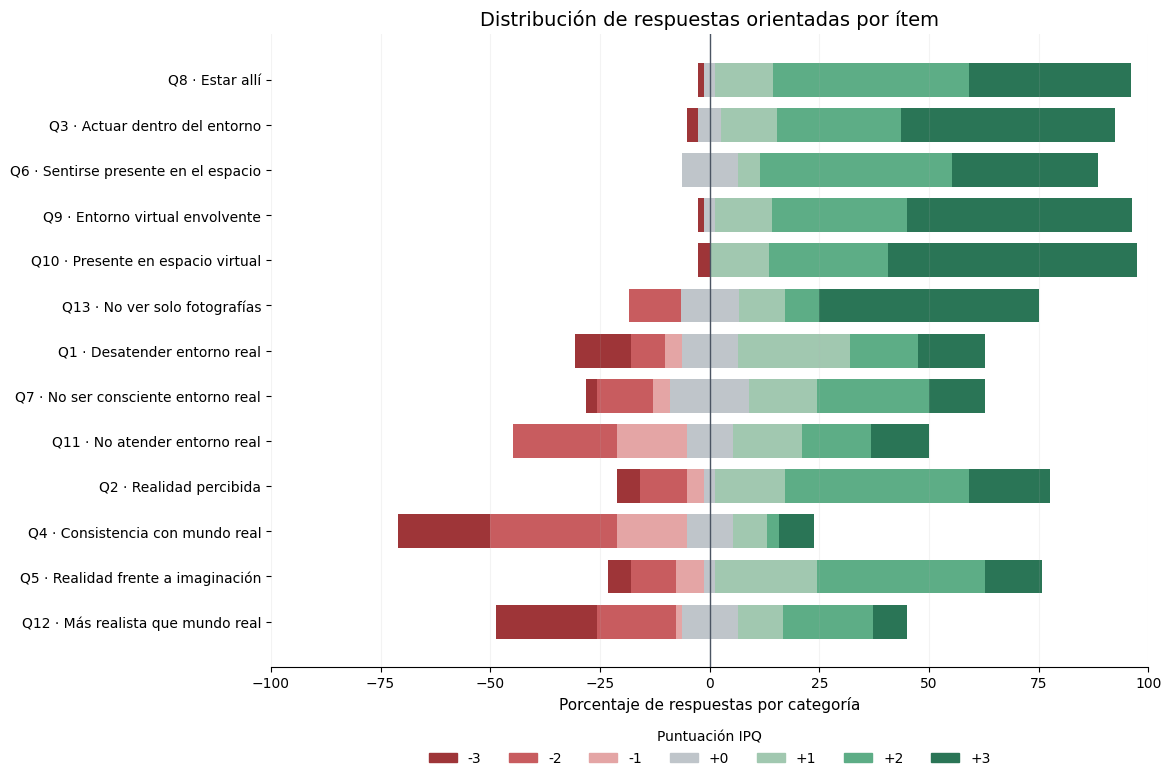

In [13]:
fig,ax=plt.subplots(figsize=(11.6,7.7),constrained_layout=True)

paleta={-3:'#9E3538',-2:'#C85C5F',-1:'#E4A5A5',0:'#BFC5CA',1:'#A1C8B0',2:'#5DAD86',3:'#2A7556'}

for y,(item,etiqueta,dim) in enumerate(items_ipq):
    datos=items_orientados[item].dropna().astype(int)
    porc={v:100*(datos==v).mean() for v in range(-3,4)}
    lado=-sum(porc[v] for v in [-3,-2,-1])
    for v in [-3,-2,-1]:
        ax.barh(y,porc[v],left=lado,color=paleta[v],height=.75)
        lado+=porc[v]
    ax.barh(y,porc[0],left=-porc[0]/2,color=paleta[0],height=.75)
    lado=porc[0]/2
    for v in [1,2,3]:
        ax.barh(y,porc[v],left=lado,color=paleta[v],height=.75)
        lado+=porc[v]

ax.set_yticks(range(len(items_ipq)),[f'{v[0].upper()} · {v[1]}' for v in items_ipq])
ax.invert_yaxis()
ax.axvline(0,color='#4B5563',lw=1)
ax.set(xlim=(-100,100),xlabel='Porcentaje de respuestas por categoría',title='Distribución de respuestas orientadas por ítem')
ax.grid(axis='x',alpha=.15)
ax.legend(handles=[Patch(color=paleta[v],label=f'{v:+d}') for v in range(-3,4)],
          bbox_to_anchor=(.5,-.08),loc='upper center',ncol=7,frameon=False,title='Puntuación IPQ')
ax.spines[['top','right','left']].set_visible(False)
plt.show()


Los ítems asociados con presencia general y espacial concentraron la mayor proporción de respuestas positivas, especialmente Q8, Q9 y Q10. En contraste, los ítems de involucramiento presentaron respuestas más variadas, mientras que Q4 y Q12 mostraron una mayor concentración de puntuaciones negativas relacionadas con el realismo.

# ⭐ 3.5 Brecha individual entre presencial espacial y realismo

Se restan las dos dimensiones de una misma persona únicamente cuando las puntuaciones están completas. Una diferencia positiva indica que la sensación espacial excede la percepción de realismo. 

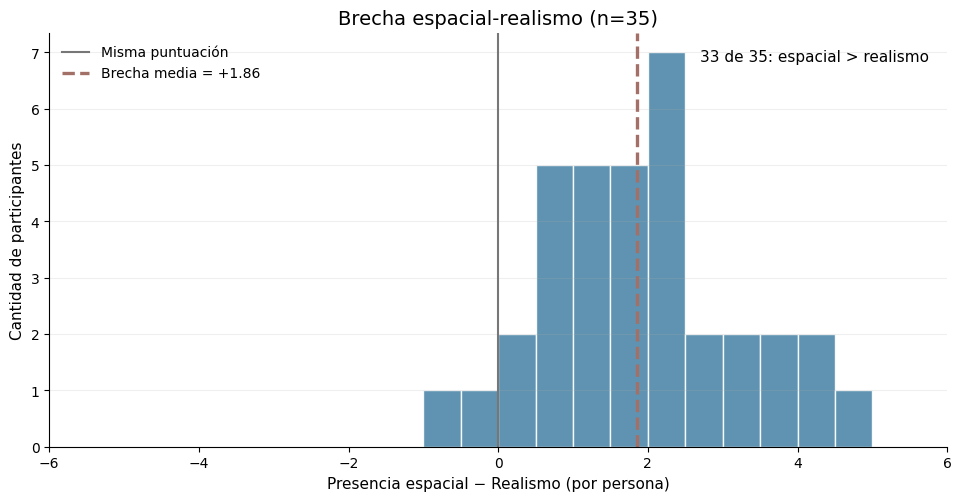

In [14]:
pares=dimensiones_ipq[['Espacial','Realismo']].dropna()
brechas=pares['Espacial']-pares['Realismo']

fig,ax=plt.subplots(figsize=(9.5,4.9),constrained_layout=True)
ax.hist(brechas,bins=np.arange(-6,6.26,.5),color='#4D87A9',edgecolor='white',alpha=.9)
ax.axvline(0,color='#777777',lw=1.5,label='Misma puntuación')
ax.axvline(brechas.mean(),color='#A27067',ls='--',lw=2.4,label=f'Brecha media = {brechas.mean():+.2f}')
ax.set(xlim=(-6,6),xlabel='Presencia espacial − Realismo (por persona)',
       ylabel='Cantidad de participantes',title=f'Brecha espacial-realismo (n={len(brechas)})')
ax.text(.98,.96,f'{int((brechas>0).sum())} de {len(brechas)}: espacial > realismo',
        transform=ax.transAxes,ha='right',va='top',fontsize=11)
ax.legend(frameon=False)
ax.grid(axis='y',alpha=.2)
ax.spines[['top','right']].set_visible(False)
plt.show()

El gráfico de Brecha espacial-realismo muestra las diferencias de las puntuaciones de presencia espacial y realismo para los 35 participantes que tienen la información válida en ambas dimensiones. Se puede observar que 33 de 35 participantes, obtuvieron una puntuación mayor en presencia espacial que en realismo. De esta misma forma se ve una diferencia promedio de 1.86 puntos a favor de la presencia espacial. 

Este resultado evidencia que, para la mayoría de los participantes, la sensación de encontrarse dentro del mundo virtual fue considerablente mayor que la percepción de realismo del entorno. Lo que diferencia a los dos aspectos de la experiencia inversiva que es el sentirse ubicado dentro de un espacio virtual y considerar que el espacio es similar al mundo físico. 





# 3.6 Sensibilidad del involucramiento al ítem 14

En la publicación de Castro et al. (2026) el ítem 14 se eliminó del modelo factorial revisado por cargas en varios factores. Aquí se compara el mismo conjunto de personas usando 3 y 4 ítems. 

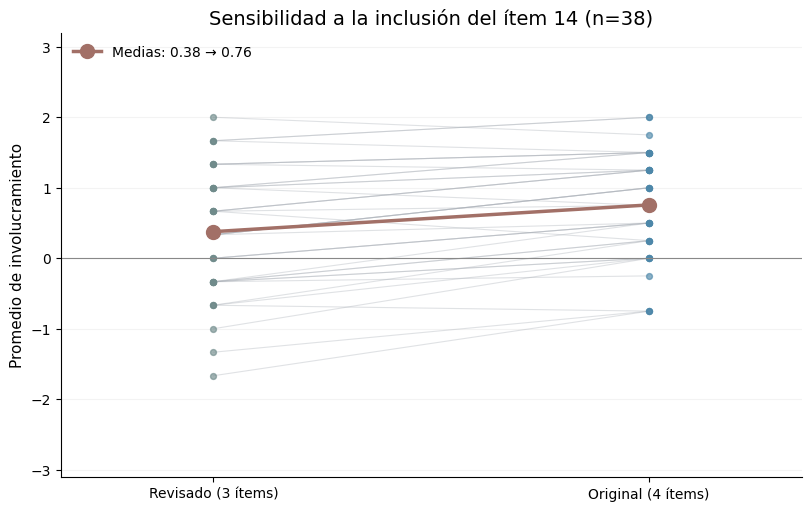

In [15]:
pares=puntuaciones[["Involucramiento (3 ítems, modelo revisado)",
                    "Involucramiento (4 ítems, sensibilidad)"]].dropna()
fig,ax=plt.subplots(figsize=(8,5),constrained_layout=True)

for _,fila in pares.iterrows():
    ax.plot([0,1],fila.values,color='#A6ACB4',lw=.8,alpha=.35,zorder=1)
ax.scatter(np.zeros(len(pares)),pares.iloc[:,0],color='#708B8B',alpha=.65,s=18,zorder=2)
ax.scatter(np.ones(len(pares)),pares.iloc[:,1],color='#4D87A9',alpha=.65,s=18,zorder=2)
ax.plot([0,1],pares.mean().values,color='#A27067',marker='o',ms=10,lw=2.5,zorder=3,
        label=f'Medias: {pares.iloc[:,0].mean():.2f} → {pares.iloc[:,1].mean():.2f}')

ax.set_xticks([0,1],['Revisado (3 ítems)','Original (4 ítems)'])
ax.set(xlim=(-.35,1.35),ylim=(-3.1,3.2),ylabel='Promedio de involucramiento',
       title=f'Sensibilidad a la inclusión del ítem 14 (n={len(pares)})')
ax.axhline(0,color='#888888',lw=.8)
ax.legend(frameon=False,loc='upper left')
ax.grid(axis='y',alpha=.15)
ax.spines[['top','right']].set_visible(False)
plt.show()


Este gráfico presenta la comparación de las puntuaciones de involucramiento usando las dos formas de cálculo: el modelo revisado de tres ítems y el modelo original de cuatro ítems. 

Los resultados muestran que, al excluir el ítem Q14, la media de involucramiento fue de 0.38, mientras que al incluirlo aumentó a 0.76. Esto representa una diferencia de 0.38 puntos entre ambas formas de calcular la dimensión.

El incremento se relaciona con la valoración favorable del ítem Q14, asociado con el grado en que el mundo virtual cautivó la atención de los participantes, cuya puntuación promedio individual fue de 1.92. Esto sugiere que los usuarios pudieron sentirse cautivados por la experiencia, aunque continuaran manteniendo cierta conciencia del entorno físico, aspecto evaluado por otros ítems de involucramiento.

La diferencia entre los dos cálculos es que demuestra la importancia de considerar la estructura del cuestionario utilizada para el análisis. En esta investigación se conserva el modelo revisado como una medida principal de involucramiento, mientras que el modelo original se presenta como un análisis complementario de sensibilidad. El incremento observado no representa una mejora de la experiencia, sino una variación derivada de incluir un ítem adicional en el cálculo.


# 3.7 Correlaciones exploratorias entre dimensiones


La matriz de Spearman describe qué puntuaciones tienden a variar juntas.

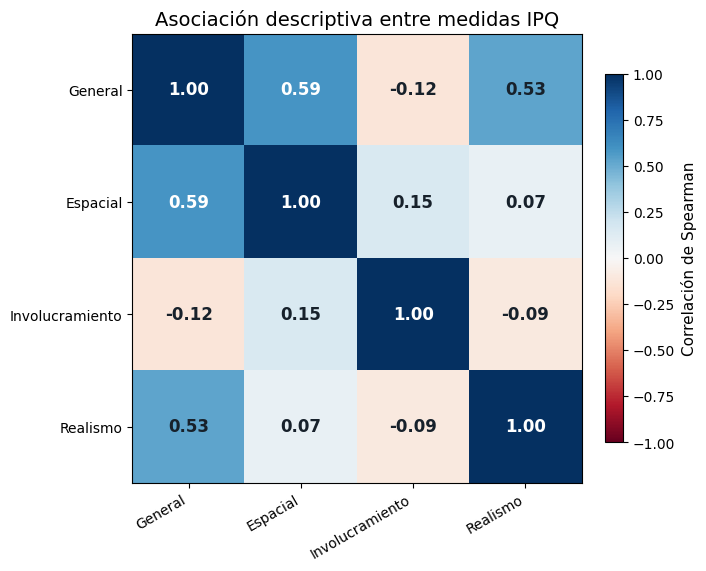

In [16]:
orden=list(dimensiones_ipq.columns)
matriz=dimensiones_ipq[orden].corr(method='spearman')
fig,ax=plt.subplots(figsize=(6.9,5.6),constrained_layout=True)
im=ax.imshow(matriz.values,cmap='RdBu',vmin=-1,vmax=1)
ax.set_xticks(range(4),orden,rotation=30,ha='right')
ax.set_yticks(range(4),orden)

for i in range(4):
    for j in range(4):
        v=matriz.iloc[i,j]
        ax.text(j,i,f'{v:.2f}',ha='center',va='center',color='white' if abs(v)>.55 else '#17212B',fontsize=12,fontweight='bold')
        
fig.colorbar(im,ax=ax,shrink=.82,label='Correlación de Spearman')
ax.set_title('Asociación descriptiva entre medidas IPQ')
plt.show()


El gráfico de asociación descriptiva entre medidas IPQ muestra las correlaciones de Spearman entre las medidas de presencia general, presencia espacial, involucramiento y realismo. Se observa una asociación positiva moderada entre la presencia general y la presencia espacial (ρ = 0.59), así como entre la presencia general y el realismo (ρ = 0.53). Estos resultados indican que los participantes con mayores puntuaciones de presencia espacial o realismo tendieron también a reportar una mayor sensación general de estar dentro del entorno virtual.

Por otro lado, la relación entre presencia general e involucramiento fue débil y negativa (ρ = −0.12). Asimismo, las asociaciones entre presencia espacial e involucramiento (ρ = 0.15), presencia espacial y realismo (ρ = 0.07), e involucramiento y realismo (ρ = −0.09) fueron cercanas a cero.

Estos resultados sugieren que las dimensiones del IPQ no necesariamente variaron de forma conjunta entre los participantes. Sentirse presente dentro del espacio virtual no implicó experimentar un mayor realismo o involucramiento. 